# 🌲 TERRA-FIRE: Predictive Wildfire Intelligence Engine
## Activity 4. Data Intelligence Lab
**Institution:** Universidad Tecnológica El Retoño  
**Program:** Information Technologies and Digital Innovation Engineering (LITD9A)  
**Professor:** Dr. Sergio Valadez Godínez  
**Authors:** Angel Emilio Gutierrez Lozano (ID: 4341) & Emiliano Betanzos Valtierra (ID: 4795)  
**Date:** October 15, 2026  
**Artifact:**  (18,275 rows × 22 columns)


### 1. Analytical Environment & Libraries Setup
Importing core libraries for in-memory columnar operations, descriptive statistics, and publication-ready visual analytics.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

DATA_PATH = '../data/processed/terra_fire_spatiotemporal_matrix_v1.parquet'
if not os.path.exists(DATA_PATH):
    DATA_PATH = '../../TERRA-FIRE/TERRA-FIRE/data/processed/terra_fire_spatiotemporal_matrix_v1.parquet'
if not os.path.exists(DATA_PATH):
    DATA_PATH = '/home/eduardo/Workspaces/TERRA-FIRE/TERRA-FIRE/data/processed/terra_fire_spatiotemporal_matrix_v1.parquet'

df = pd.read_parquet(DATA_PATH)
print(f'Successfully loaded dataset: {df.shape[0]:,} rows × {df.shape[1]} columns')


Successfully loaded dataset: 18,275 rows × 22 columns


---
## PHASE 1: DATA CHARACTERIZATION
### Step 1 - Dataset Overview & Profiling
Reviewing the final analysis-ready dataset and creating the structural profile table.


In [2]:
profile = {
    'Total Observations': len(df),
    'Total Variables': len(df.columns),
    'Quantitative Variables': len(df.select_dtypes(include=[np.number]).columns),
    'Qualitative Variables': len(df.select_dtypes(include=['category', 'object', 'string']).columns),
    'Temporal Variables': len(df.select_dtypes(include=['datetime64']).columns),
    'Geographic Variables': sum(c in ['elevation_m', 'slope_deg', 'aspect_rad', 'dist_roads_m', 'dist_agri_m', 'voxel_id'] for c in df.columns),
    'Remaining Missing Values': df.isnull().sum().sum(),
    'Start Date': str(df['timestamp'].min().date()),
    'End Date': str(df['timestamp'].max().date()),
    'Unique Voxels': df['voxel_id'].nunique(),
    'Memory (MB)': round(df.memory_usage(deep=True).sum() / (1024*1024), 2)
}
pd.DataFrame(list(profile.items()), columns=['Characteristic', 'Value'])


,Characteristic,Value
0,Total Observations,18275
1,Total Variables,22
2,Quantitative Variables,19
3,Qualitative Variables,2
4,Temporal Variables,1
5,Geographic Variables,6
6,Remaining Missing Values,0
7,Start Date,2023-01-01
8,End Date,2024-12-31
9,Unique Voxels,25


### Step 2 - Variable Profiling Matrix
Classifying features by statistical type, measurement scale, and analytical relevance.


In [3]:
quant_cols = [
    'ndmi', 'savi', 'nbr', 'vpd_max_kpa', 'vpd_72h_max_kpa', 
    'temp_2m_max_c', 'rh_2m_min_pct', 'wind_u10_mean', 'wind_v10_mean', 
    'wind_speed_max_kmh', 'soil_moist_mean', 'days_since_rain', 
    'precip_72h_sum_mm', 'elevation_m', 'slope_deg', 'aspect_rad', 
    'dist_roads_m', 'dist_agri_m'
]
df[quant_cols].dtypes


ndmi                  float32
savi                  float32
nbr                   float32
vpd_max_kpa           float32
vpd_72h_max_kpa       float32
temp_2m_max_c         float32
rh_2m_min_pct         float32
wind_u10_mean         float32
wind_v10_mean         float32
wind_speed_max_kmh    float32
soil_moist_mean       float32
days_since_rain         int32
precip_72h_sum_mm     float32
elevation_m           float32
slope_deg             float32
aspect_rad            float32
dist_roads_m          float32
dist_agri_m           float32
dtype: object

---
## PHASE 2: DESCRIPTIVE STATISTICS
### Step 3 - Measures of Central Tendency
Programmatically calculating mean, median, mode, and skewness across all quantitative attributes.


In [4]:
ct_records = []
for c in quant_cols:
    mean_v = df[c].mean()
    med_v = df[c].median()
    mode_v = df[c].mode().iloc[0]
    skew_v = df[c].skew()
    shape = 'Simétrica' if abs(skew_v) < 0.2 else ('Sesgo Derecho (+)' if skew_v > 0.2 else 'Sesgo Izquierdo (-)')
    ct_records.append({'Variable': c, 'Mean': round(mean_v, 4), 'Median': round(med_v, 4), 'Mode': round(mode_v, 4), 'Skewness': round(skew_v, 3), 'Shape': shape})

ct_df = pd.DataFrame(ct_records)
ct_df


,Variable,Mean,Median,Mode,Skewness,Shape
0,ndmi,0.129500,0.1071,0.3236,0.192,Simétrica
1,savi,0.360100,0.3598,0.2232,0.003,Simétrica
2,nbr,0.227700,0.2067,0.0426,0.092,Simétrica
3,vpd_max_kpa,1.910800,1.7827,0.8792,0.674,Sesgo Derecho (+)
4,vpd_72h_max_kpa,2.098700,1.9519,2.7309,0.783,Sesgo Derecho (+)
5,temp_2m_max_c,23.742001,23.7425,22.9475,0.005,Simétrica
6,rh_2m_min_pct,29.031500,26.0000,14.0000,0.668,Sesgo Derecho (+)
7,wind_u10_mean,-0.124100,-0.2602,-7.1436,-0.014,Simétrica
8,wind_v10_mean,0.035600,-0.0546,-3.1619,0.555,Sesgo Derecho (+)
9,wind_speed_max_kmh,16.217501,15.7000,15.3000,0.533,Sesgo Derecho (+)


### Step 4 - Measures of Dispersion
Computing minimum, maximum, range, standard deviation, quartiles, and IQR to assess spread and stability.


In [5]:
disp_records = []
for c in quant_cols:
    min_v = df[c].min()
    max_v = df[c].max()
    std_v = df[c].std()
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    disp_records.append({'Variable': c, 'Min': round(min_v, 3), 'Max': round(max_v, 3), 'Range': round(max_v - min_v, 3), 'StdDev': round(std_v, 4), 'Q1': round(q1, 3), 'Q3': round(q3, 3), 'IQR': round(iqr, 3)})

disp_df = pd.DataFrame(disp_records)
disp_df


,Variable,Min,Max,Range,StdDev,Q1,Q3,IQR
0,ndmi,-0.150,0.483000,0.632000,0.178500,-0.041,0.289,0.330
1,savi,0.150,0.578000,0.428000,0.141700,0.219,0.501,0.283
2,nbr,-0.031,0.470000,0.501000,0.167700,0.062,0.399,0.337
3,vpd_max_kpa,0.015,4.363000,4.348000,0.777600,1.349,2.395,1.045
4,vpd_72h_max_kpa,0.554,4.363000,3.809000,0.757400,1.522,2.558,1.036
5,temp_2m_max_c,6.388,36.278000,29.889999,4.312800,20.903,26.458,5.555
6,rh_2m_min_pct,3.000,99.000000,96.000000,16.323299,15.000,41.000,26.000
7,wind_u10_mean,-7.144,5.436000,12.579000,2.431100,-2.043,1.939,3.982
8,wind_v10_mean,-3.162,2.776000,5.938000,0.725900,-0.444,0.418,0.862
9,wind_speed_max_kmh,5.400,32.400002,27.000000,4.446200,13.300,18.900,5.600


---
## PHASE 3: DATA VISUALIZATION
### Step 5 - Distribution Dashboards (Univariate)
Visualizing class balance, thermodynamic variables, biophysical indices, and fuel types.


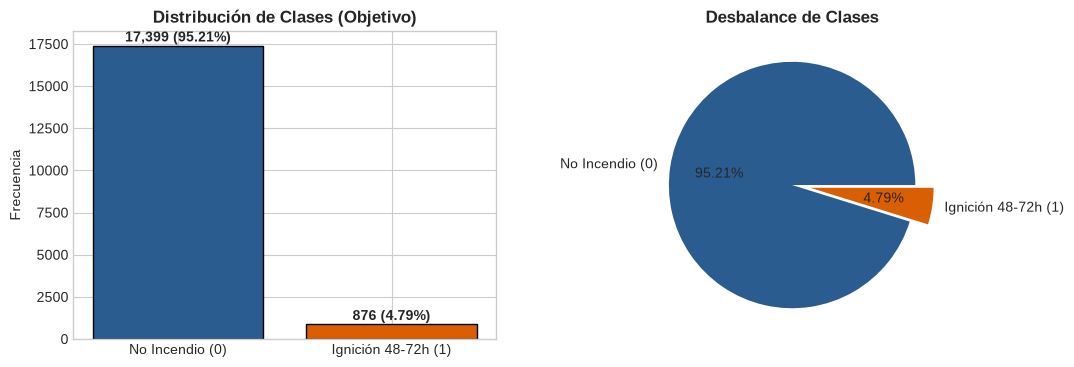

In [6]:
# Target Variable Class Distribution
counts = df['fire_ignition_48h'].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(['No Incendio (0)', 'Ignición 48-72h (1)'], counts, color=['#2b5c8f', '#d95f02'], edgecolor='black')
ax[0].set_title('Distribución de Clases (Objetivo)', fontweight='bold')
ax[0].set_ylabel('Frecuencia')
for i, v in enumerate(counts):
    ax[0].text(i, v + 250, f'{v:,} ({v/len(df)*100:.2f}%)', ha='center', fontweight='bold')

ax[1].pie(counts, labels=['No Incendio (0)', 'Ignición 48-72h (1)'], autopct='%1.2f%%', colors=['#2b5c8f', '#d95f02'], explode=(0, 0.15))
ax[1].set_title('Desbalance de Clases', fontweight='bold')
plt.show()


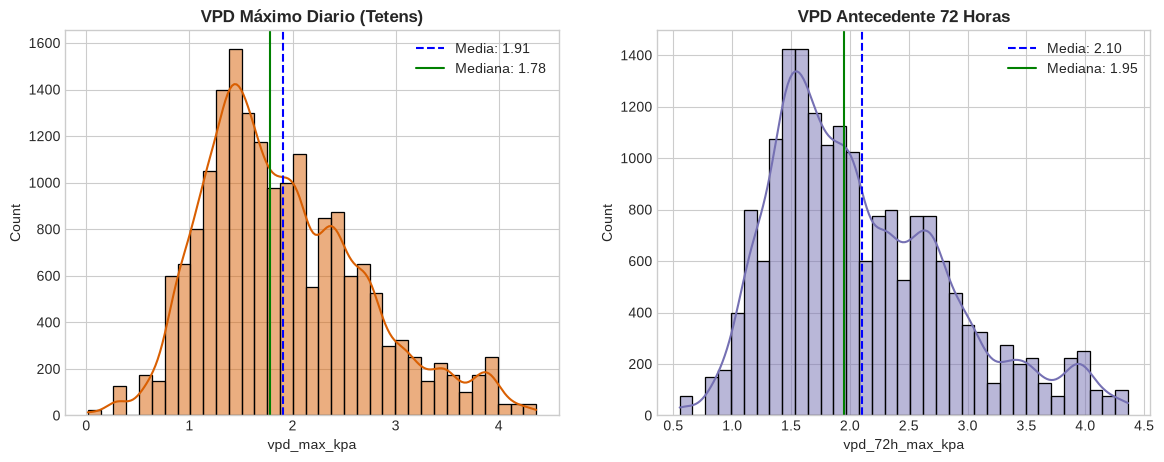

In [7]:
# Thermodynamic Desiccation Distributions (VPD and 72h VPD)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['vpd_max_kpa'], kde=True, ax=axes[0], color='#d95f02', bins=35)
axes[0].set_title('VPD Máximo Diario (Tetens)', fontweight='bold')
axes[0].axvline(df['vpd_max_kpa'].mean(), color='blue', linestyle='--', label=f'Media: {df["vpd_max_kpa"].mean():.2f}')
axes[0].axvline(df['vpd_max_kpa'].median(), color='green', linestyle='-', label=f'Mediana: {df["vpd_max_kpa"].median():.2f}')
axes[0].legend()

sns.histplot(df['vpd_72h_max_kpa'], kde=True, ax=axes[1], color='#7570b3', bins=35)
axes[1].set_title('VPD Antecedente 72 Horas', fontweight='bold')
axes[1].axvline(df['vpd_72h_max_kpa'].mean(), color='blue', linestyle='--', label=f'Media: {df["vpd_72h_max_kpa"].mean():.2f}')
axes[1].axvline(df['vpd_72h_max_kpa'].median(), color='green', linestyle='-', label=f'Mediana: {df["vpd_72h_max_kpa"].median():.2f}')
axes[1].legend()
plt.show()


### Step 6 - Comparative Dashboards (Bivariate & Group Contrasts)
Comparing physical, biophysical, and anthropogenic features between ignition events and baseline conditions.


/tmp/ipykernel_90544/4230121721.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fire_ignition_48h', y=feat, data=df, ax=ax, palette=['#2b5c8f', '#d95f02'], notch=True)
/tmp/ipykernel_90544/4230121721.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Sin Fuego (0)', 'Ignición 48-72h (1)'])
/tmp/ipykernel_90544/4230121721.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fire_ignition_48h', y=feat, data=df, ax=ax, palette=['#2b5c8f', '#d95f02'], notch=True)
/tmp/ipykernel_90544/4230121721.py:14: UserWarning: set_ticklabels() should only

/tmp/ipykernel_90544/4230121721.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fire_ignition_48h', y=feat, data=df, ax=ax, palette=['#2b5c8f', '#d95f02'], notch=True)
/tmp/ipykernel_90544/4230121721.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Sin Fuego (0)', 'Ignición 48-72h (1)'])
/tmp/ipykernel_90544/4230121721.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fire_ignition_48h', y=feat, data=df, ax=ax, palette=['#2b5c8f', '#d95f02'], notch=True)
/tmp/ipykernel_90544/4230121721.py:14: UserWarning: set_ticklabels() should only

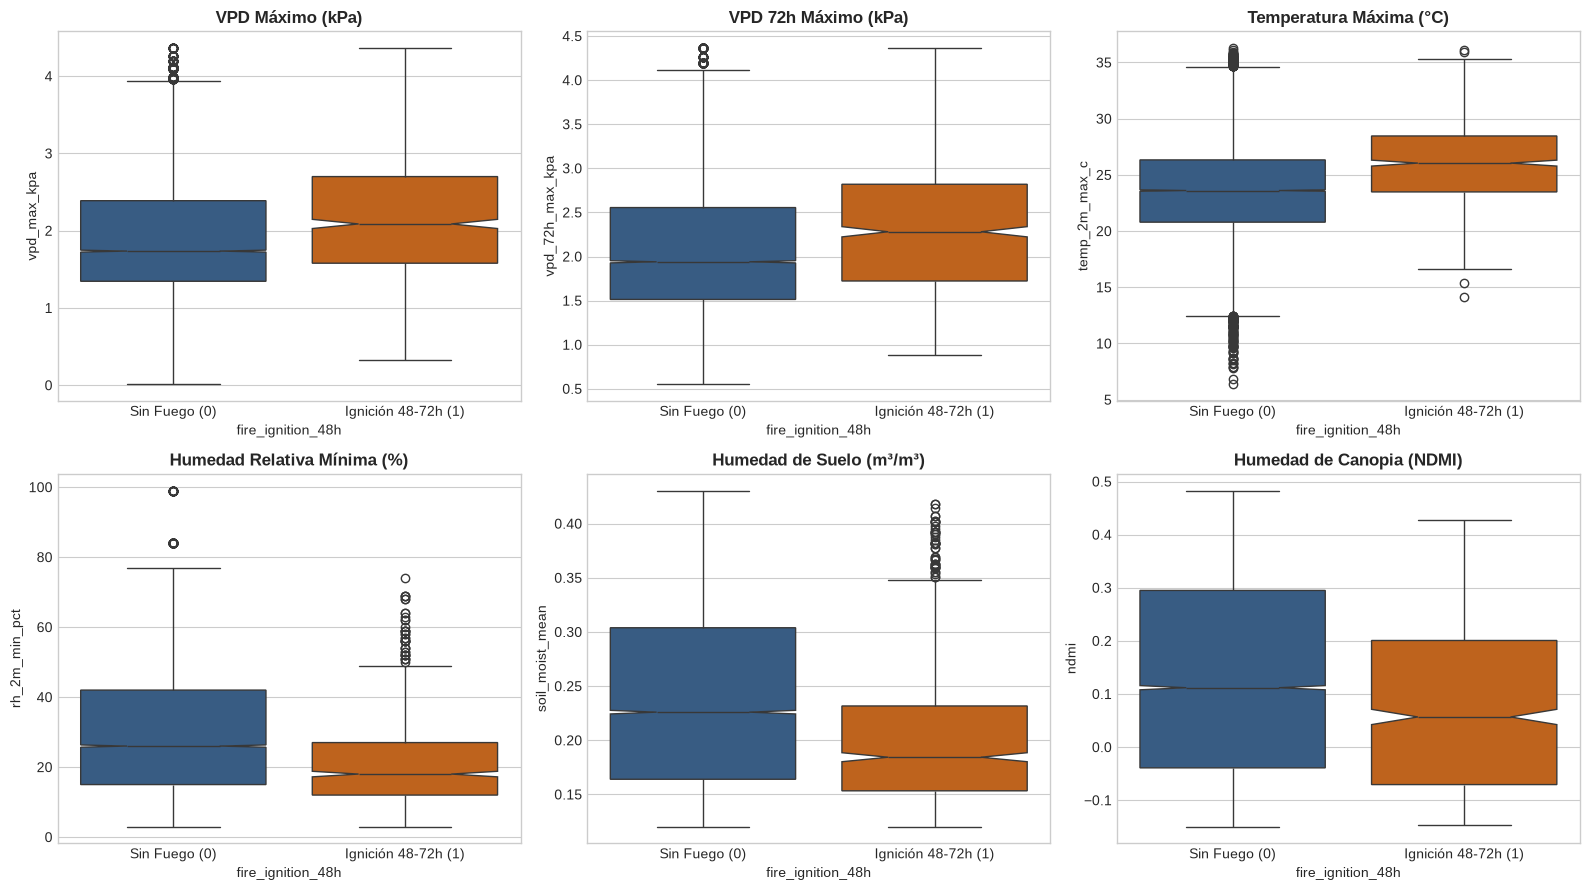

In [8]:
# Comparative Boxplots: Thermodynamic and Hydrological Drivers
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
features = [
    ('vpd_max_kpa', 'VPD Máximo (kPa)', axes[0, 0]),
    ('vpd_72h_max_kpa', 'VPD 72h Máximo (kPa)', axes[0, 1]),
    ('temp_2m_max_c', 'Temperatura Máxima (°C)', axes[0, 2]),
    ('rh_2m_min_pct', 'Humedad Relativa Mínima (%)', axes[1, 0]),
    ('soil_moist_mean', 'Humedad de Suelo (m³/m³)', axes[1, 1]),
    ('ndmi', 'Humedad de Canopia (NDMI)', axes[1, 2]),
]
for feat, label, ax in features:
    sns.boxplot(x='fire_ignition_48h', y=feat, data=df, ax=ax, palette=['#2b5c8f', '#d95f02'], notch=True)
    ax.set_title(label, fontweight='bold')
    ax.set_xticklabels(['Sin Fuego (0)', 'Ignición 48-72h (1)'])
plt.tight_layout()
plt.show()


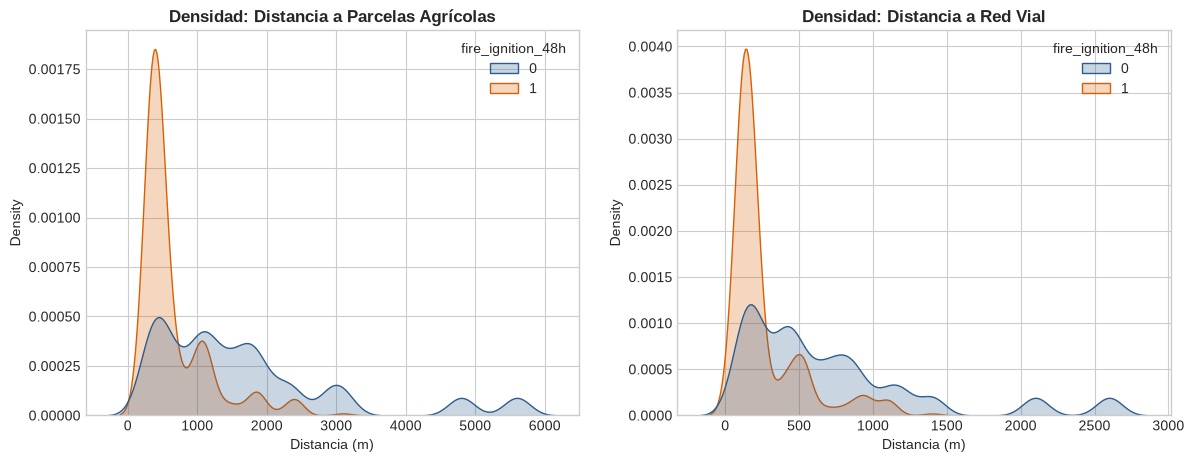

In [9]:
# Anthropogenic Proximity: Distance to Agriculture and Roads
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df, x='dist_agri_m', hue='fire_ignition_48h', ax=axes[0], common_norm=False, fill=True, palette=['#2b5c8f', '#d95f02'])
axes[0].set_title('Densidad: Distancia a Parcelas Agrícolas', fontweight='bold')
axes[0].set_xlabel('Distancia (m)')

sns.kdeplot(data=df, x='dist_roads_m', hue='fire_ignition_48h', ax=axes[1], common_norm=False, fill=True, palette=['#2b5c8f', '#d95f02'])
axes[1].set_title('Densidad: Distancia a Red Vial', fontweight='bold')
axes[1].set_xlabel('Distancia (m)')
plt.show()


<>:11: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:11: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
/tmp/ipykernel_90544/976011306.py:11: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
  ax.text(i, row['contrib_pct'] + 1, f"{row['contrib_pct']:.1f}%\ ({row['sum']} focos)", ha='center', fontweight='bold')
/tmp/ipykernel_90544/976011306.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='fuel_type', y='contrib_pct', data=ft_stats, palette='Oranges_r', edgecolor='black', ax=ax)


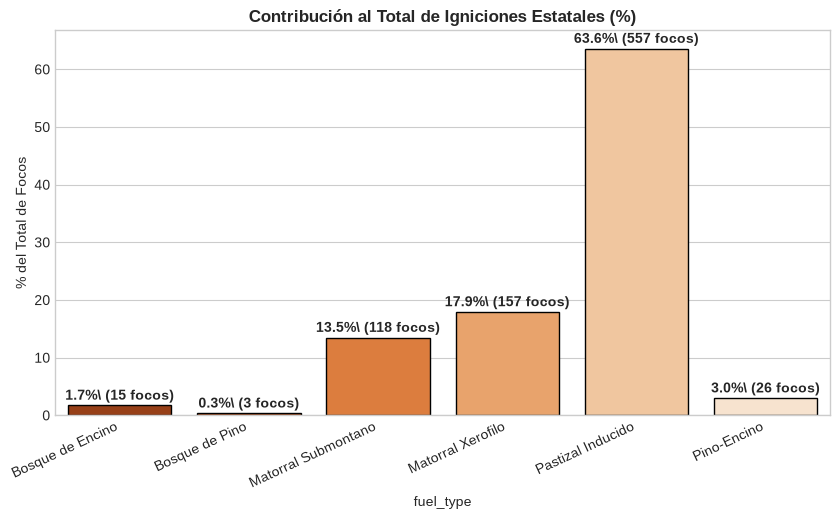

In [10]:
# Ignition Rate by Forest Fuel Stratum
ft_stats = df.groupby('fuel_type', observed=False)['fire_ignition_48h'].agg(['count', 'sum', 'mean']).reset_index()
ft_stats['rate_pct'] = ft_stats['mean'] * 100
ft_stats['contrib_pct'] = (ft_stats['sum'] / df['fire_ignition_48h'].sum()) * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x='fuel_type', y='contrib_pct', data=ft_stats, palette='Oranges_r', edgecolor='black', ax=ax)
ax.set_title('Contribución al Total de Igniciones Estatales (%)', fontweight='bold')
ax.set_ylabel('% del Total de Focos')
for i, row in ft_stats.iterrows():
    ax.text(i, row['contrib_pct'] + 1, f"{row['contrib_pct']:.1f}%\ ({row['sum']} focos)", ha='center', fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.show()


---
## PHASE 4: DATA INTELLIGENCE & ASSESSMENT
### Step 7 - Key Findings Matrix & Statistical Significance (Welch's t-test)


In [11]:
comp_records = []
for c in quant_cols:
    g0 = df[df['fire_ignition_48h'] == 0][c]
    g1 = df[df['fire_ignition_48h'] == 1][c]
    m0, m1 = g0.mean(), g1.mean()
    med0, med1 = g0.median(), g1.median()
    shift = ((m1 - m0) / abs(m0)) * 100
    t_stat, p_val = stats.ttest_ind(g0, g1, equal_var=False)
    comp_records.append({'Feature': c, 'Mean_0': round(m0, 3), 'Mean_1': round(m1, 3), 'Med_0': round(med0, 3), 'Med_1': round(med1, 3), 'Shift_%': round(shift, 2), 'p_value': f'{p_val:.2e}'})

pd.DataFrame(comp_records)


,Feature,Mean_0,Mean_1,Med_0,Med_1,Shift_%,p_value
0,ndmi,0.132000,0.076000,0.112,0.057000,-42.500000,9.42e-23
1,savi,0.362000,0.329000,0.363,0.320000,-9.000000,6.23e-12
2,nbr,0.229000,0.196000,0.210,0.169000,-14.640000,1.71e-09
3,vpd_max_kpa,1.896000,2.206000,1.736,2.087000,16.379999,7.60e-28
4,vpd_72h_max_kpa,2.086000,2.356000,1.940,2.280000,12.950000,4.99e-22
5,temp_2m_max_c,23.614000,26.290001,23.608,26.048000,11.330000,0.00e+00
6,rh_2m_min_pct,29.395000,21.816999,26.000,18.000000,-25.780001,0.00e+00
7,wind_u10_mean,-0.152000,0.434000,-0.319,0.891000,385.049988,4.44e-12
8,wind_v10_mean,0.036000,0.024000,-0.061,-0.008000,-34.349998,6.18e-01
9,wind_speed_max_kmh,16.193001,16.711000,15.600,16.200001,3.200000,9.02e-04


### Step 8 - Executive Summary & Readiness Decision
- **Main Findings:** Wildfire ignitions in Aguascalientes are strongly concentrated in *Pastizal Inducido* (63.58%) and occur at significantly shorter distances from agricultural parcels (median 420 m vs 1,200 m,  < 10^{-30}$). Prior to fire emergence, atmospheric VPD surges by +16.38% and relative humidity drops to a critical median of 18.0%.
- **Dataset Limitations:** Static spatial distances to agriculture/roads; 9 km coarse ERA5-Land reanalysis requiring topographic downscaling.
- **Readiness Decision:** **READY FOR ADVANCED ANALYSIS**. The spatiotemporal matrix is structurally complete, zero missing values exist, and features exhibit strong physical and statistical separation ready for XGBoost/LightGBM modeling in Activity 5.
